# 集成學習與提升法 (Ensemble Learning & Boosting) 

> Ensemble Learning 並不是讓所有機器學習模型都能額外安裝的「強化配件」，而是一種結合多個模型預測結果的學習策略。
>
> Bagging 可以搭配不同基礎模型；Random Forest、AdaBoost、Gradient Boosting 與 XGBoost 則通常直接作為獨立的集成模型使用。

## Ensemble Learning (集成學習)

假設你正在評估一間房子的合理租金。你找了三位房仲估價：

| 房仲 | 預測月租金    | 判斷依據     |
| -- | -------- | -------- |
| A  | 18,000 元 | 房屋坪數、屋齡  |
| B  | 21,000 元 | 地點、交通便利性 |
| C  | 20,000 元 | 房間數、停車位  |

三位房仲的預測不一樣，因為每個人掌握的資訊、評估方式與經驗不同。如果只相信其中一個人，可能會受到個別判斷誤差影響。但如果將三個人的預測取平均：

$$ \hat{y}=\frac{18000+21000+20000}{3}=19666.67 $$

我們得到約 19,667 元的估計結果。

集成學習也是類似概念：「讓多個模型一起解決相同的問題，再整合各個模型的預測，降低單一模型判斷失誤造成的影響。」

不過，如果三位房仲都使用錯誤的市場資訊，平均結果也不會自動變準。機器學習也是如此，模型之間的差異與個別預測品質都很重要。

### 單一模型與集成模型

不同的樹會找到不同的切割規則。集成學習便嘗試把這些不同的判斷結合起來。

![](./assets/單一模型與集成模型.png)

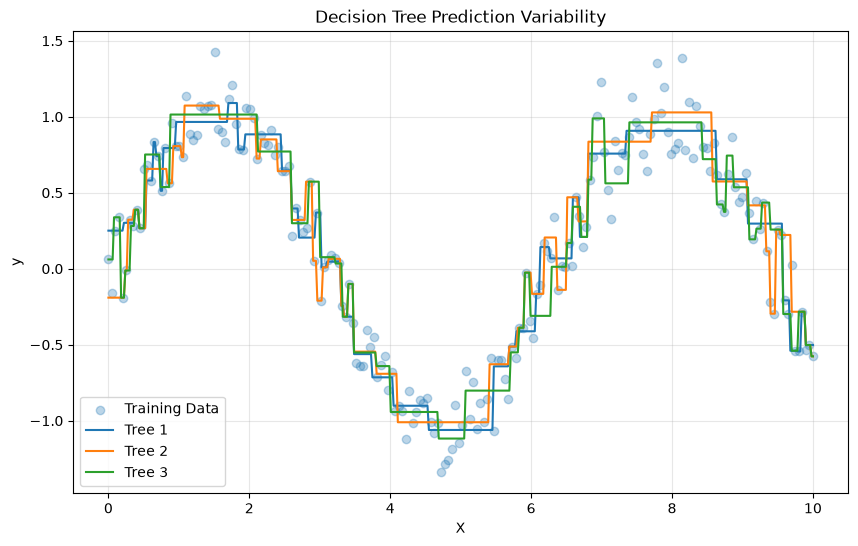

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.tree import DecisionTreeRegressor


### 建立模擬資料
rng = np.random.default_rng(42)

X = np.linspace(0, 10, 200).reshape(-1, 1) # 建立 200 個輸入數值
y = np.sin(X.ravel()) + rng.normal(0, 0.2, 200) # 建立非線性資料並加入雜訊


### 建立預測範圍
X_plot = np.linspace(0, 10, 500).reshape(-1, 1)


### 建立畫布
plt.figure(figsize=(10, 6))


### 繪製原始資料
plt.scatter(X, y, alpha=0.3, label="Training Data")


### 使用不同的訓練樣本建立決策樹
for seed in [1, 2, 3]:

    ### 隨機抽取訓練資料
    sample_rng = np.random.default_rng(seed)
    sample_index = sample_rng.choice(
        len(X),
        size=120,
        replace=False
    )

    ### 建立決策樹
    model = DecisionTreeRegressor(
        max_depth=6,
        random_state=42
    )

    ### 訓練模型
    model.fit(X[sample_index], y[sample_index])

    ### 進行預測
    y_pred = model.predict(X_plot)

    ### 繪製預測曲線
    plt.plot(X_plot, y_pred, label=f"Tree {seed}")


### 設定圖表
plt.xlabel("X")
plt.ylabel("y")
plt.title("Decision Tree Prediction Variability")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### 集成學習的四種常見方式

![](./assets/集成學習的四種常見方式.png)

#### Bagging 與 Boosting 的本質差異

- Bagging 比較像找多位專家各自提出意見，再整合結果。
- Boosting 則比較像一位學生反覆訂正考卷。每一次練習都針對前一次尚未學好的部分進行改善。
- 兩者都使用多個模型，但解決問題的方式不同。

## Bagging (Bootstrap Aggregating)

### Bagging 到底在做什麼？

假設我們只有一份包含 1,000 間房屋的租金資料。如果訓練 100 棵完全相同的 Decision Tree，而且每棵樹都使用相同的資料與設定，這些樹很可能學出相同或非常接近的結果。這樣建立 100 棵樹，未必有明顯幫助。

Bagging 的做法是：讓每個模型看到略有不同的訓練資料。

它透過 Bootstrap Sampling 建立不同的訓練樣本，讓各個模型學到不同的規則，再整合預測結果。

### Bootstrap Sampling (自助抽樣法)

![](./assets/Bootstrap_Sampling.png)

In [ ]:
import numpy as np
import pandas as pd


### 建立原始資料
df = pd.DataFrame({
    "house_id": ["A", "B", "C", "D", "E"],
    "monthly_rent": [12000, 15000, 18000, 20000, 25000]
})


### 建立隨機產生器
rng = np.random.default_rng(42)


### 進行三次 Bootstrap Sampling
for i in range(3):

    ### 從原始資料中進行有放回抽樣
    sample_index = rng.choice(
        len(df),
        size=len(df), # 每次抽取 5 筆
        replace=True # 允許同一筆資料重複抽中
        # 可以嘗試將 `replace=True` 改成 `replace=False`，觀察結果有什麼差別。
    )

    ### 取得抽樣資料
    sample_df = df.iloc[sample_index]

    print(f"\nBootstrap Sample {i + 1}")
    display(sample_df)


Bootstrap Sample 1


,house_id,monthly_rent
0,A,12000
3,D,20000
3,D,20000
2,C,18000
2,C,18000



Bootstrap Sample 2


,house_id,monthly_rent
4,E,25000
0,A,12000
3,D,20000
1,B,15000
0,A,12000



Bootstrap Sample 3


,house_id,monthly_rent
2,C,18000
4,E,25000
3,D,20000
3,D,20000
3,D,20000


### 為什麼常說 Bootstrap 只有約 63.2% 的不同資料？

假設原始資料有 1,000 筆，我們進行 1,000 次有放回抽樣。雖然總共抽出 1,000 筆，但因為某些資料會重複出現，因此不同資料的數量通常少於 1,000 筆。

當資料量夠大時，平均大約只有 63.2% 的原始樣本至少被抽中一次。剩下約 36.8% 沒有被抽中的資料，稱為 Out-of-Bag (OOB) 資料。

這裡可以直接用程式驗證。

In [4]:
import numpy as np


### 設定原始資料數量
n_samples = 1000


### 建立隨機產生器
rng = np.random.default_rng(42)


### 進行 Bootstrap Sampling
sample_index = rng.choice(
    n_samples,
    size=n_samples,
    replace=True
)


### 計算不同樣本的數量
unique_count = len(np.unique(sample_index))


### 計算沒有被抽中的資料數量
oob_count = n_samples - unique_count


### 顯示結果
print("原始資料數量：", n_samples)
print("不同樣本數量：", unique_count)
print("OOB 資料數量：", oob_count)

print("不同樣本比例：", unique_count / n_samples)
print("OOB 比例：", oob_count / n_samples)

原始資料數量： 1000
不同樣本數量： 637
OOB 資料數量： 363
不同樣本比例： 0.637
OOB 比例： 0.363



### 實作：比較單一 Decision Tree 與 Bagging

這個實驗使用相同的模擬資料，比較兩種模型的測試誤差。

In [5]:
import numpy as np
import pandas as pd

from sklearn.datasets import make_regression
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import BaggingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


### 建立模擬迴歸資料
X, y = make_regression(
    n_samples=1000, # 建立 1000 筆資料
    n_features=8, # 每筆資料包含 8 個 Features
    n_informative=5, # 其中 5 個 Features 與 Target 有關
    noise=20, # 加入隨機雜訊
    random_state=42
)


### 切分 Train / Test
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)


### 建立單一 Decision Tree
tree_model = DecisionTreeRegressor(
    max_depth=8,
    random_state=42
)


### 建立 Bagging 模型
bagging_model = BaggingRegressor(
    estimator=DecisionTreeRegressor(
        max_depth=8,
        random_state=42
    ),
    n_estimators=100,
    max_samples=0.8,
    bootstrap=True,
    random_state=42,
    n_jobs=-1
)


### 建立模型字典
models = {
    "Decision Tree": tree_model,
    "Bagging": bagging_model
}


### 儲存評估結果
results = []


### 依序訓練與評估
for name, model in models.items():

    ### 訓練模型
    model.fit(X_train, y_train)

    ### 預測測試資料
    y_pred = model.predict(X_test)

    ### 計算評估指標
    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)

    ### 儲存結果
    results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R²": r2
    })


### 顯示比較結果
results_df = pd.DataFrame(results)
print(results_df.round(3))

           Model     MAE    RMSE     R²
0  Decision Tree  48.979  61.715  0.760
1        Bagging  33.458  43.220  0.882


### 實作：觀察 n_estimators 的影響

這裡讓學生觀察樹的數量增加時，RMSE 是否會持續下降。

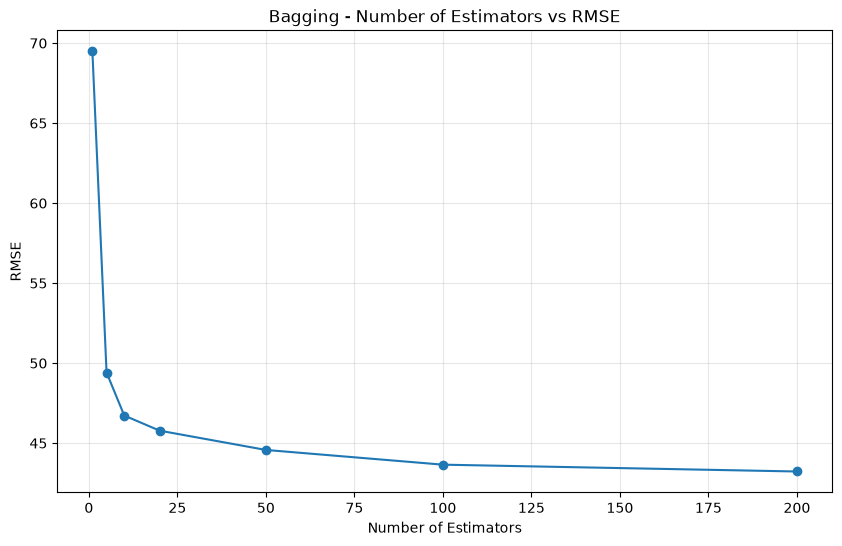

In [6]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.ensemble import BaggingRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_squared_error


### 設定要測試的樹數量
n_estimators_list = [1, 5, 10, 20, 50, 100, 200]


### 儲存每個設定的 RMSE
rmse_list = []


### 逐一測試
for n in n_estimators_list:

    ### 建立 Bagging 模型
    model = BaggingRegressor(
        estimator=DecisionTreeRegressor(
            max_depth=8,
            random_state=42
        ),
        n_estimators=n, # 使用不同的樹數量
        random_state=42,
        n_jobs=-1
    )

    ### 訓練模型
    model.fit(X_train, y_train)

    ### 預測測試資料
    y_pred = model.predict(X_test)

    ### 計算 RMSE
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    rmse_list.append(rmse)


### 建立畫布
plt.figure(figsize=(10, 6))


### 繪製樹數量與 RMSE 的關係
plt.plot(
    n_estimators_list,
    rmse_list,
    marker="o"
)


### 設定圖表
plt.xlabel("Number of Estimators")
plt.ylabel("RMSE")
plt.title("Bagging - Number of Estimators vs RMSE")
plt.grid(alpha=0.3)
plt.show()

## Random Forest (隨機森林深入解析)

### Random Forest 與 Bagging 的關係

前面已經學過 Bagging 會讓多棵 Decision Tree 使用不同的訓練樣本。但這樣還有一個問題。

假設我們要預測房租，資料包含：

```text
坪數
屋齡
樓層
房間數
距離捷運站
是否有停車位
```

如果「坪數」與租金的關係非常強，許多決策樹可能都會優先選擇坪數進行分裂。結果就是，雖然每棵樹的訓練資料不同，但樹的結構可能還是非常相似。

Random Forest 的做法是：「除了隨機抽取訓練資料，還能在每次節點分裂時，隨機選擇部分 Features 進行比較。」

例如：

```text
Decision Tree A
可考慮：坪數、屋齡、樓層

Decision Tree B
可考慮：坪數、房間數、停車位

Decision Tree C
可考慮：屋齡、樓層、距離捷運站
```

這樣不同的樹就有機會找到不同的預測規則。

### Random Forest 的完整運作流程

![](./assets/Random%20Forest.png)

### Random Forest 的常用參數

```python
from sklearn.ensemble import RandomForestRegressor

### 建立 Random Forest Regression 模型
model = RandomForestRegressor(
    n_estimators=200, # 建立 200 棵決策樹
    criterion="squared_error", # 使用平方誤差評估分裂品質
    max_depth=12, # 每棵樹最大深度為 12
    min_samples_split=4, # 節點至少 4 筆資料才允許分裂
    min_samples_leaf=2, # 每個葉節點至少保留 2 筆資料
    max_features=0.8, # 每次分裂隨機考慮 80% 的 Features
    bootstrap=True, # 使用 Bootstrap 抽樣
    oob_score=True, # 計算 OOB 評估分數
    random_state=42, # 固定隨機種子
    n_jobs=-1 # 使用所有可用 CPU 工作程序
)
```

### 實作：觀察 max_depth 對模型的影響

樹越深，模型就能建立越複雜的判斷規則。但如果樹太深，模型可能把訓練資料的雜訊也學進去。這個實驗比較不同 `max_depth` 的 Train 與 Validation RMSE。


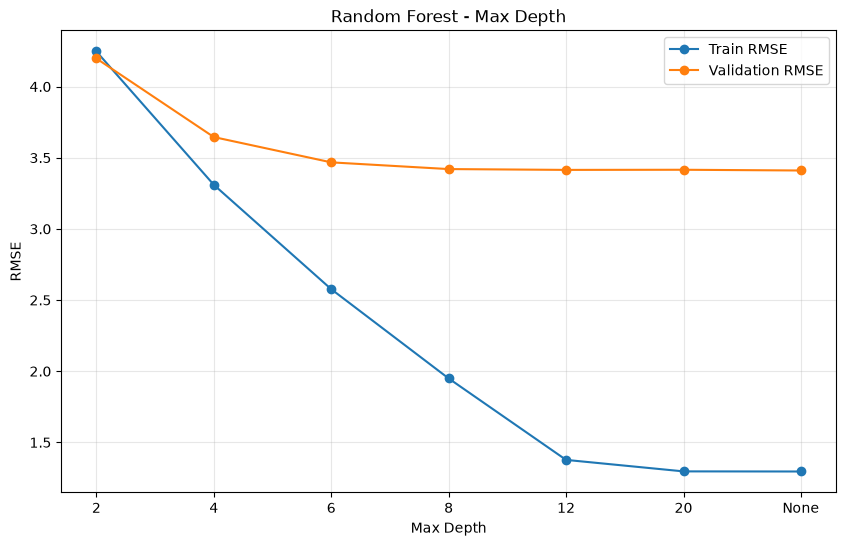

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import make_friedman1
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error


### 建立非線性模擬資料
X, y = make_friedman1(
    n_samples=1200,
    n_features=10,
    noise=3.0,
    random_state=42
)


### 切分 Train / Validation
X_train, X_valid, y_train, y_valid = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42
)


### 設定要測試的最大深度
depth_list = [2, 4, 6, 8, 12, 20, None]


### 儲存評估結果
train_rmse_list = []
valid_rmse_list = []


### 逐一測試不同深度
for depth in depth_list:

    ### 建立 Random Forest
    model = RandomForestRegressor(
        n_estimators=100,
        max_depth=depth, # 調整樹的最大深度
        random_state=42,
        n_jobs=-1
    )

    ### 訓練模型
    model.fit(X_train, y_train)

    ### 預測 Train 與 Validation
    y_train_pred = model.predict(X_train)
    y_valid_pred = model.predict(X_valid)

    ### 計算 RMSE
    train_rmse = np.sqrt(mean_squared_error(y_train, y_train_pred))
    valid_rmse = np.sqrt(mean_squared_error(y_valid, y_valid_pred))

    ### 儲存結果
    train_rmse_list.append(train_rmse)
    valid_rmse_list.append(valid_rmse)


### 將 None 轉成圖表標籤
depth_labels = [str(depth) for depth in depth_list]


### 建立畫布
plt.figure(figsize=(10, 6))


### 繪製 Train RMSE
plt.plot(
    depth_labels,
    train_rmse_list,
    marker="o",
    label="Train RMSE"
)


### 繪製 Validation RMSE
plt.plot(
    depth_labels,
    valid_rmse_list,
    marker="o",
    label="Validation RMSE"
)


### 設定圖表
plt.xlabel("Max Depth")
plt.ylabel("RMSE")
plt.title("Random Forest - Max Depth")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# 可以觀察到：
# - 深度太小時，Train 與 Validation 的誤差可能都很高。
# - 深度增加後，Train 誤差通常下降。
# - Validation 誤差可能下降後趨於穩定，甚至再次上升。

### Feature Importance (特徵重要性)

Random Forest 除了預測，還可以協助我們了解模型主要依賴哪些 Features。

```python
import pandas as pd


### 取得 Feature Importance
importance_df = pd.DataFrame({
    "Feature": X_train.columns, # 取得訓練資料的欄位名稱
    "Importance": model.feature_importances_ # 取得各欄位的重要性
})


### 按重要性由高到低排序
importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

print(importance_df)
```

例如房租預測模型可能得到以下結果：

| Feature | Importance (示範) |
| ------- | --------------- |
| 坪數      | 0.42            |
| 距離捷運站   | 0.25            |
| 屋齡      | 0.15            |
| 房間數     | 0.10            |
| 樓層      | 0.05            |
| 停車位     | 0.03            |

這些是示範數值，不是實際模型結果。

如果坪數的重要性是 0.42，代表它對模型的節點不純度下降貢獻較大，不代表坪數增加 1 坪，租金就一定增加固定金額。

### 實作：Feature Importance 視覺化

      Feature  Importance
8   Feature_9    0.012562
9  Feature_10    0.012670
5   Feature_6    0.013446
7   Feature_8    0.013479
6   Feature_7    0.013583
2   Feature_3    0.062876
4   Feature_5    0.100861
0   Feature_1    0.203135
1   Feature_2    0.229843
3   Feature_4    0.337544


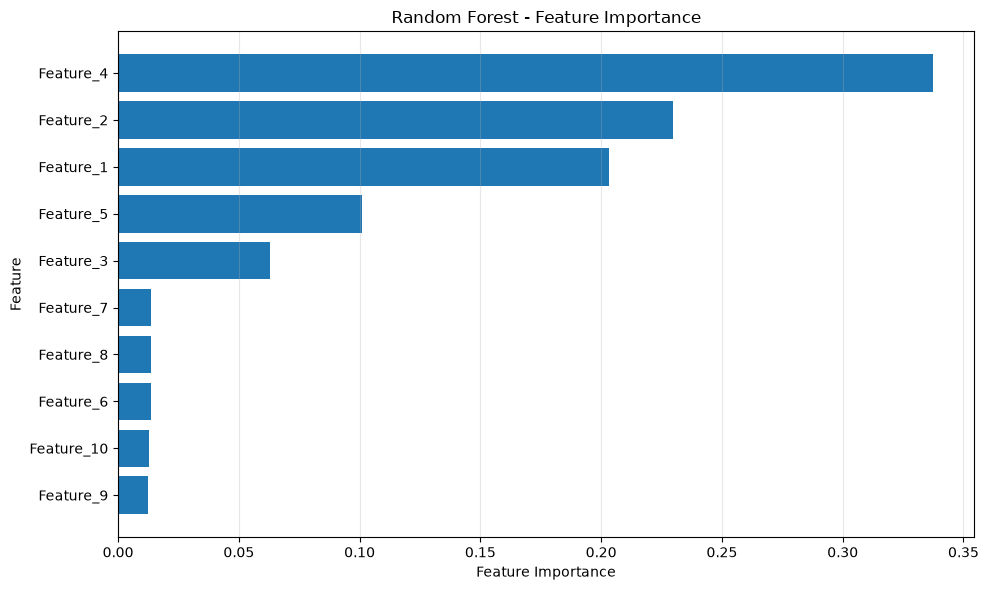

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_friedman1
from sklearn.ensemble import RandomForestRegressor


### 建立模擬資料
X, y = make_friedman1(
    n_samples=1000, # 建立 1000 筆資料
    n_features=10, # 每筆資料有 10 個 Features
    noise=1.0, # 加入隨機雜訊
    random_state=42 # 固定隨機種子
)


### 建立欄位名稱
feature_names = [f"Feature_{i}" for i in range(1, 11)]


### 建立 Random Forest 模型
model = RandomForestRegressor(
    n_estimators=200, # 建立 200 棵決策樹
    random_state=42, # 固定隨機種子
    n_jobs=-1 # 使用所有可用 CPU 工作程序
)


### 訓練模型
model.fit(X, y)


### 建立 Feature Importance 表格
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": model.feature_importances_
})


### 依照重要性排序
importance_df = importance_df.sort_values(
    by="Importance",
    ascending=True
)


### 顯示 Feature Importance
print(importance_df)


### 繪製水平長條圖
plt.figure(figsize=(10, 6))

plt.barh(
    importance_df["Feature"],
    importance_df["Importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Random Forest - Feature Importance")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

## AdaBoost (Adaptive Boosting)

Bagging 的想法是讓多個模型各自學習，再整合結果。

但我們可以換一個角度思考：假設學生正在練習數學考卷，第一次考試錯了 20 題。下一次練習時，如果他仍然平均複習全部題目，可能會浪費時間在已經熟悉的題型上。更有效率的做法可能是針對上次答錯的題型加強練習。

Boosting 就有類似的概念。它不是讓每個模型完全獨立訓練，而是讓後面的模型根據前面模型的表現，調整學習方向。

![](./assets/為什麼會出現%20Boosting.png)

### 實作：使用 AdaBoost 進行二元分類

這次使用 scikit-learn 產生模擬客戶資料，預測客戶是否購買商品。

In [2]:
import pandas as pd

from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import AdaBoostClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score


### 建立模擬分類資料
X, y = make_classification(
    n_samples=1000, # 建立 1000 筆資料
    n_features=10, # 每筆資料有 10 個 Features
    n_informative=6, # 其中 6 個 Features 與答案有關
    n_redundant=2, # 其中 2 個 Features 為冗餘特徵
    random_state=42
)


### 切分 Train / Test
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y, # 保持分類比例
    random_state=42
)


### 建立 AdaBoost 模型
model = AdaBoostClassifier(
    estimator=DecisionTreeClassifier(
        max_depth=1,
        random_state=42
    ),
    n_estimators=100,
    learning_rate=0.1,
    random_state=42
)


### 訓練模型
model.fit(X_train, y_train)


### 預測分類結果
y_pred = model.predict(X_test)


### 預測正類別機率
y_score = model.predict_proba(X_test)[:, 1]


### 計算評估指標
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)


### 顯示結果
print(f"Accuracy：{accuracy:.4f}")
print(f"Precision：{precision:.4f}")
print(f"Recall：{recall:.4f}")
print(f"F1-score：{f1:.4f}")


### 查看前 10 筆預測
result_df = pd.DataFrame({
    "Actual": y_test[:10],
    "Predicted": y_pred[:10],
    "Probability": y_score[:10]
})

print(result_df)

Accuracy：0.7950
Precision：0.7360
Recall：0.9200
F1-score：0.8178
   Actual  Predicted  Probability
0       1          0     0.227909
1       0          1     0.689537
2       0          0     0.206330
3       0          0     0.364176
4       1          1     0.716059
5       1          1     0.689537
6       1          0     0.364176
7       1          1     0.583268
8       0          1     0.583268
9       0          0     0.318993


## Gradient Boosting (梯度提升法)

### Gradient Boosting 在做什麼？

AdaBoost 透過調整樣本權重，讓後面的模型更加關注先前預測錯誤的資料。

Gradient Boosting 則使用另一種方式：「讓新的模型學習目前預測還需要修正多少。」

假設我們要預測房屋租金，第一個模型預測得不夠準確。與其直接丟掉這個模型，重新訓練一個更複雜的模型，不如保留原本的預測，再訓練一棵新樹，專門學習如何修正錯誤。這樣一棵接著一棵，逐步改善整體預測。

### Residual (殘差) 是什麼？

在迴歸問題中，Residual 就是真實值與預測值之間的差距。

$$
\boxed{\text{Residual}=\text{Actual}-\text{Predicted}}
$$

例如：

| 房屋 | 真實租金   | 預測租金   | Residual |
| -- | ------ | ------ | -------- |
| A  | 12,000 | 15,000 | -3,000   |
| B  | 18,000 | 15,000 | +3,000   |
| C  | 21,000 | 15,000 | +6,000   |
| D  | 24,000 | 15,000 | +9,000   |

從這張表可以發現：

- Residual 為正數：模型預測太低。
- Residual 為負數：模型預測太高。
- Residual 接近 0：模型預測接近真實值。

Gradient Boosting 在平方誤差迴歸中，會讓後續決策樹學習這些殘差，改善目前的預測。

### Gradient Boosting 如何逐步修正預測？

假設有四間房屋：

```
真實租金：

A：12000
B：18000
C：21000
D：24000
```

為了簡化說明，第一個模型先使用平均租金作為預測。

\\[ \frac{12000+18000+21000+24000}{4}=18750 \\]

因此第一輪的預測都是 18,750 元。

| 房屋 | 真實租金   | 第一輪預測  | 殘差     |
| -- | ------ | ------ | ------ |
| A  | 12,000 | 18,750 | -6,750 |
| B  | 18,000 | 18,750 | -750   |
| C  | 21,000 | 18,750 | +2,250 |
| D  | 24,000 | 18,750 | +5,250 |

接著訓練一棵 Decision Tree，讓它學習這些殘差。

假設這棵樹對房屋 A 預測的修正值是 -6,000 元，Learning Rate 設為 0.1。

更新後：

$$ 
\hat{y}\_{new}=18750+0.1\times(-6000)
$$

$$
\boxed{\hat{y}\_{new}=18150}
$$

雖然 18,150 元仍然高於真實租金 12,000 元，但已經比原本的 18,750 元更接近。

接下來的樹會繼續學習尚未修正的誤差。

### Learning Rate (學習率)

Learning Rate 控制每一棵新樹對整體預測的影響程度。

假設目前預測為 18,000 元，新樹建議增加 4,000 元。

| Learning Rate | 實際修正   | 更新後預測  |
| ------------- | ------ | ------ |
| 1.0           | +4,000 | 22,000 |
| 0.5           | +2,000 | 20,000 |
| 0.1           | +400   | 18,400 |
| 0.01          | +40    | 18,040 |

學習率越小，每次修正的幅度通常越小。但不是越小越好。如果 Learning Rate 太小，卻沒有增加足夠的 Boosting 階段，模型可能學習不足。因此 `learning_rate` 與 `n_estimators` 通常需要一起調整。

![](./assets/Gradient_Boosting.png)

### 實作：觀察 Gradient Boosting 如何逐步學習

學生可以觀察 `n_estimators=1` 時，模型只能建立簡單的預測曲線；隨著 Boosting 階段增加，曲線逐漸能夠描述更複雜的非線性關係。

但如果模型持續學習訓練資料中的雜訊，也可能產生 Overfitting。

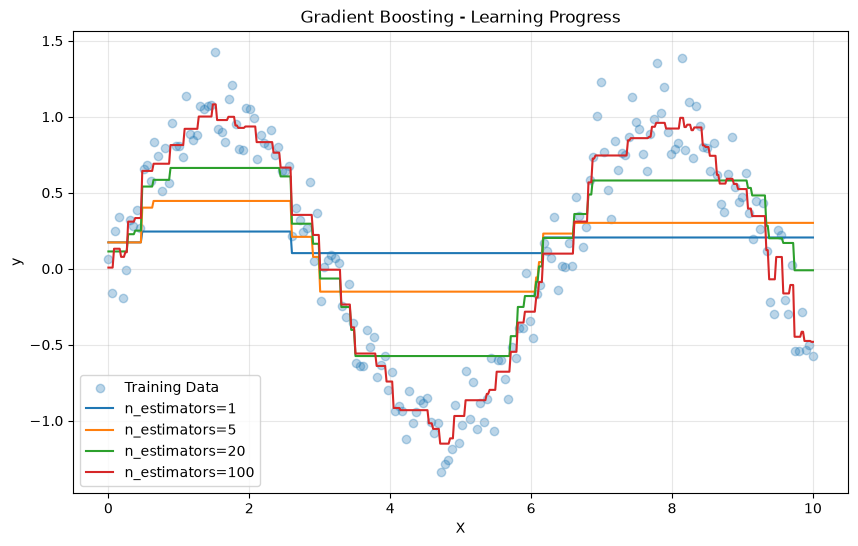

In [3]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.ensemble import GradientBoostingRegressor


### 建立模擬資料
rng = np.random.default_rng(42)

X = np.linspace(0, 10, 200).reshape(-1, 1)
y = np.sin(X.ravel()) + rng.normal(0, 0.2, 200)


### 建立預測範圍
X_plot = np.linspace(0, 10, 500).reshape(-1, 1)


### 設定要比較的 Boosting 階段數量
n_estimators_list = [1, 5, 20, 100]


### 建立畫布
plt.figure(figsize=(10, 6))


### 繪製原始資料
plt.scatter(
    X,
    y,
    alpha=0.3,
    label="Training Data"
)


### 測試不同的 n_estimators
for n in n_estimators_list:

    ### 建立模型
    model = GradientBoostingRegressor(
        n_estimators=n,
        learning_rate=0.1,
        max_depth=2,
        random_state=42
    )

    ### 訓練模型
    model.fit(X, y)

    ### 預測
    y_pred = model.predict(X_plot)

    ### 繪製預測曲線
    plt.plot(
        X_plot,
        y_pred,
        label=f"n_estimators={n}"
    )


### 設定圖表
plt.xlabel("X")
plt.ylabel("y")
plt.title("Gradient Boosting - Learning Progress")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### 實作：觀察每一輪的 RMSE

scikit-learn 提供 `staged_predict()`，可以查看每個 Boosting 階段結束後的預測。

這對理解 Gradient Boosting 很有幫助。

這個實驗能讓學生觀察模型是否出現：

```text
Train RMSE 持續下降
        ↓
Validation RMSE 先下降
        ↓
Validation RMSE 開始停滯或上升
        ↓
模型可能開始 Overfitting
```

最佳階段： 254
最低 Validation RMSE： 2.2234656786694758


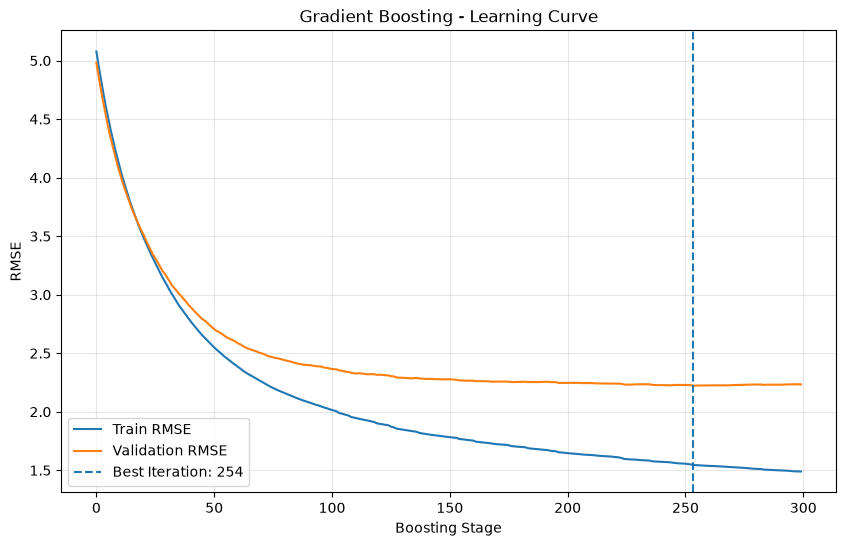

In [4]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import make_friedman1
from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_squared_error


### 建立模擬資料
X, y = make_friedman1(
    n_samples=1500,
    n_features=10,
    noise=2.0,
    random_state=42
)


### 切分 Train / Validation
X_train, X_valid, y_train, y_valid = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)


### 建立模型
model = GradientBoostingRegressor(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=3,
    random_state=42
)


### 訓練模型
model.fit(X_train, y_train)


### 儲存每個階段的 RMSE
train_rmse_list = []
valid_rmse_list = []


### 取得每個階段的預測
train_predictions = model.staged_predict(X_train)
valid_predictions = model.staged_predict(X_valid)


### 計算每個階段的 RMSE
for y_train_pred, y_valid_pred in zip(
    train_predictions,
    valid_predictions
):

    ### Train RMSE
    train_rmse = np.sqrt(
        mean_squared_error(y_train, y_train_pred)
    )

    ### Validation RMSE
    valid_rmse = np.sqrt(
        mean_squared_error(y_valid, y_valid_pred)
    )

    train_rmse_list.append(train_rmse)
    valid_rmse_list.append(valid_rmse)


### 找出 Validation RMSE 最低的階段
best_iteration = np.argmin(valid_rmse_list) + 1

print("最佳階段：", best_iteration)
print("最低 Validation RMSE：", min(valid_rmse_list))


### 建立畫布
plt.figure(figsize=(10, 6))


### 繪製 Train RMSE
plt.plot(
    train_rmse_list,
    label="Train RMSE"
)


### 繪製 Validation RMSE
plt.plot(
    valid_rmse_list,
    label="Validation RMSE"
)


### 標記最佳階段
plt.axvline(
    best_iteration - 1,
    linestyle="--",
    label=f"Best Iteration: {best_iteration}"
)


### 設定圖表
plt.xlabel("Boosting Stage")
plt.ylabel("RMSE")
plt.title("Gradient Boosting - Learning Curve")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## XGBoost (Extreme Gradient Boosting)

XGBoost 是 Extreme Gradient Boosting 的縮寫。它延續 Gradient Boosting 的核心概念：逐步建立新的樹，改善目前模型的預測結果。但它額外加入了許多提高訓練效率、控制模型複雜度與改善泛化能力的設計。

假設我們要分析 100 萬筆房屋交易資料。傳統 Gradient Boosting 也能處理這類任務，但隨著資料量增加，訓練時間可能變長。XGBoost 透過高效的建樹演算法、平行化與正則化等技術，讓模型在許多表格資料任務中具有競爭力。不過XGBoost 並不保證比 Random Forest 或其他模型準確。實際效果仍然取決於資料、參數與驗證方式。

### Regularization (正則化)

假設我們建立一個房租預測模型。

- 模型 A 使用非常複雜的規則，幾乎記住每一筆訓練資料。
- 模型 B 使用比較簡單的規則，雖然訓練誤差略高，但對沒看過的房屋也能保持不錯的預測能力。
- 我們通常更希望模型具有 B 的泛化能力。

Regularization 的目的就是在降低預測誤差的同時，限制模型過度複雜。

![](./assets/XGBoost.png)

### 實作：使用 XGBoost 預測房屋租金

In [6]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from xgboost import XGBRegressor


### 讀取資料集
df = pd.read_csv("./data/ensemble_rent.csv")


### 移除重複資料與 Target 缺失值
df = df.drop_duplicates()
df = df.dropna(subset=["monthly_rent"])


### 選擇 Features 與 Target
X = df.drop(columns=["monthly_rent"])
y = df["monthly_rent"]


### 切分 Train / Test
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)


### 選擇數值與類別欄位
numeric_features = X.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X.select_dtypes(
    exclude=["number"]
).columns.tolist()


### 建立數值前處理
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])


### 建立類別前處理
categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])


### 建立 ColumnTransformer
preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])


### 建立 XGBoost 模型
xgb_model = XGBRegressor(
    objective="reg:squarederror",
    n_estimators=300,
    learning_rate=0.05,
    max_depth=4,
    subsample=0.8,
    colsample_bytree=0.8,
    tree_method="hist",
    random_state=42,
    n_jobs=-1
)


### 建立完整 Pipeline
model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", xgb_model)
])


### 訓練模型
model.fit(X_train, y_train)


### 使用模型預測
y_pred = model.predict(X_test)


### 計算評估指標
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)


### 顯示結果
print(f"MAE：{mae:.2f}")
print(f"RMSE：{rmse:.2f}")
print(f"R²：{r2:.4f}")

MAE：1912.25
RMSE：2366.98
R²：0.9232


### 實作：觀察 Learning Rate 對 XGBoost 的影響

這次比較不同 Learning Rate 的預測表現。

為了公平比較，固定其他參數，只改變 `learning_rate`。

   Learning Rate         RMSE
0           0.01  2906.872890
1           0.05  2505.256374
2           0.10  2548.122544
3           0.30  2686.038719


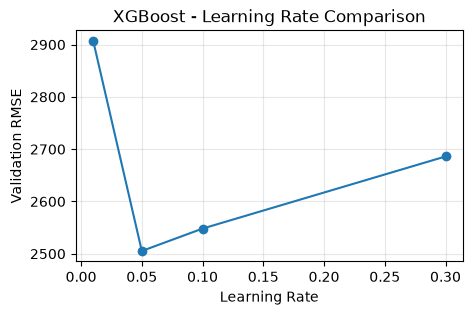

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from xgboost import XGBRegressor


### 從原本的訓練集再切出 Validation
X_fit, X_valid, y_fit, y_valid = train_test_split(
    X_train,
    y_train,
    test_size=0.25,
    random_state=42
)


### 設定不同 Learning Rate
learning_rates = [0.01, 0.05, 0.1, 0.3]


### 儲存比較結果
results = []


### 逐一測試
for lr in learning_rates:

    ### 建立 XGBoost 模型
    xgb_model = XGBRegressor(
        objective="reg:squarederror",
        n_estimators=200,
        learning_rate=lr, # 使用不同的 Learning Rate
        max_depth=4,
        random_state=42,
        n_jobs=-1
    )

    ### 建立 Pipeline
    model = Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("model", xgb_model)
    ])

    ### 訓練模型
    model.fit(X_fit, y_fit)

    ### 預測 Validation
    y_pred = model.predict(X_valid)

    ### 計算 RMSE
    rmse = np.sqrt(
        mean_squared_error(y_valid, y_pred)
    )

    ### 儲存結果
    results.append({
        "Learning Rate": lr,
        "RMSE": rmse
    })


### 顯示結果
results_df = pd.DataFrame(results)
print(results_df)


### 視覺化
plt.figure(figsize=(5, 3))

plt.plot(
    results_df["Learning Rate"],
    results_df["RMSE"],
    marker="o"
)

plt.xlabel("Learning Rate")
plt.ylabel("Validation RMSE")
plt.title("XGBoost - Learning Rate Comparison")
plt.grid(alpha=0.3)
plt.show()

## Bagging、Random Forest、AdaBoost、Gradient Boosting、XGBoost 綜合比較

學完五種模型後，學生應該已經知道各模型的運作方式，但還有一個很實際的問題：

如果拿到一份新的資料集，到底該選哪一個模型？答案不是直接選 XGBoost，而是讓模型在相同的資料切分、前處理與評估指標下進行比較。

### 五種模型比較表

| 比較項目  | Bagging   | Random Forest     | AdaBoost | Gradient Boosting | XGBoost  |
| ----- | --------- | ----------------- | -------- | ----------------- | -------- |
| 學習方式  | 平行        | 平行                | 循序       | 循序                | 循序       |
| 主要原理  | Bootstrap | Bootstrap + 特徵隨機性 | 調整樣本權重   | 學習負梯度             | 最佳化梯度提升  |
| 主要優勢  | 降低變異      | 穩定、容易使用           | 弱學習器組合   | 非線性擬合能力           | 高效、參數彈性大 |
| 主要限制  | 模型可能太相似   | 記憶體成本             | 對雜訊可能敏感  | 需要控制過擬合           | 調參較複雜    |
| 適合初學者 | 高         | 高                 | 中        | 中                 | 中        |